# Parihaka Seismic U-Net Baseline

Google Colab / NVIDIA L4 workflow. Select a GPU runtime, then run the cells in order.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/parihaka_dino_unet'
import os, sys
os.chdir(PROJECT_ROOT)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
print('PROJECT_ROOT =', PROJECT_ROOT)

Mounted at /content/drive
PROJECT_ROOT = /content/drive/MyDrive/parihaka_dino_unet


In [2]:
!pip -q install -r requirements_colab.txt

import torch, numpy as np
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision('high')
print('torch', torch.__version__)
print('cuda available', torch.cuda.is_available())
if torch.cuda.is_available():
    print('gpu', torch.cuda.get_device_name(0))
    print('bf16 supported', torch.cuda.is_bf16_supported())

torch 2.11.0+cu130
cuda available True
gpu NVIDIA RTX PRO 6000 Blackwell Server Edition
bf16 supported True


In [3]:
# MLflow is optional: remote tracking is enabled when a DagsHub token is available.
import os
DAGSHUB_USER = 'dragnellstr'
DAGSHUB_REPO = 'sismoML'
os.environ['MLFLOW_TRACKING_URI'] = f'https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}.mlflow'
os.environ['MLFLOW_TRACKING_USERNAME'] = DAGSHUB_USER
if not os.environ.get('MLFLOW_TRACKING_PASSWORD'):
    try:
        from google.colab import userdata
        token = userdata.get('DAGSHUB_TOKEN')
        if token:
            os.environ['MLFLOW_TRACKING_PASSWORD'] = token
    except Exception:
        pass
USE_MLFLOW = bool(os.environ.get('MLFLOW_TRACKING_PASSWORD'))
if USE_MLFLOW:
    os.environ['MLFLOW_ENABLE_SYSTEM_METRICS_LOGGING'] = 'true'
print('MLflow enabled:', USE_MLFLOW)


MLflow enabled: True


In [4]:
from src.config import load_config, ensure_output_dirs, resolve_path

CONFIG_PATH = 'configs/comparison_seismic_unet.yaml'  # Residual U-Net from scratch: matched train/validation/test comparison
USER_CONFIG = {
    'project_root': PROJECT_ROOT,
    'data': {
        'train_seismic': 'data/TrainingData_Image.segy',
        'train_labels': 'data/TrainingData_Labels.segy',
        'test1_seismic': 'data/TestData_Image1.segy',
        'test2_seismic': 'data/TestData_Image2.segy',
    },
    'tracking': {'mlflow': {'enabled': USE_MLFLOW}},
    # Matched budget: batch 32 x accumulation 4 = effective batch 128.
    # If the GPU runs out of memory: 'training': {'batch_size': 16, 'gradient_accumulation': 8},
}
cfg = load_config(CONFIG_PATH, USER_CONFIG)
ensure_output_dirs(cfg)
cfg

{'seed': 42,
 'project_root': '/content/drive/MyDrive/parihaka_dino_unet',
 'data': {'train_seismic': 'data/TrainingData_Image.segy',
  'train_labels': 'data/TrainingData_Labels.segy',
  'test1_seismic': 'data/TestData_Image1.segy',
  'test2_seismic': 'data/TestData_Image2.segy',
  'axis_order': 'inline_crossline_depth'},
 'cache': {'dir': 'cache', 'mmap': True},
 'outputs': {'dir': 'outputs/comparison_v2/seismic_unet',
  'checkpoints': 'outputs/comparison_v2/seismic_unet/checkpoints',
  'predictions': 'outputs/comparison_v2/seismic_unet/predictions',
  'logs': 'outputs/comparison_v2/seismic_unet/logs',
  'figures': 'outputs/comparison_v2/seismic_unet/figures'},
 'tracking': {'mlflow': {'enabled': True,
   'tracking_uri': 'https://dagshub.com/dragnellstr/sismoML.mlflow',
   'experiment_name': 'parihaka-three-model-comparison-v2',
   'run_name': 'seismic_unet-comparison-v2',
   'log_system_metrics': True,
   'log_checkpoints': False}},
 'split': {'axis': 'inline',
  'train_fraction': 0.

In [5]:
from src.cache import load_or_create_volume_cache
from src.segy_io import read_segy_volume, validate_label_volume

cache_dir = resolve_path(cfg, cfg['cache']['dir'])
train_seismic, train_meta = load_or_create_volume_cache(resolve_path(cfg, cfg['data']['train_seismic']), cache_dir, 'train_seismic', read_segy_volume, mmap=cfg['cache']['mmap'])
train_labels, label_meta = load_or_create_volume_cache(resolve_path(cfg, cfg['data']['train_labels']), cache_dir, 'train_labels', read_segy_volume, mmap=cfg['cache']['mmap'])
assert train_seismic.shape == train_labels.shape, (train_seismic.shape, train_labels.shape)
validate_label_volume(train_labels)
print('train shape', train_seismic.shape)
print('train read method', train_meta['reader']['read_method'], train_meta['reader'].get('iline_count'), train_meta['reader'].get('xline_count'))
print('label read method', label_meta['reader']['read_method'], label_meta['reader'].get('iline_count'), label_meta['reader'].get('xline_count'))
if train_meta['reader']['read_method'] != 'segyio.tools.cube' or label_meta['reader']['read_method'] != 'segyio.tools.cube':
    raise RuntimeError('Could not read SEG-Y as a geometry cube. Check the cache, data, and headers before training.')
print('label values 1..6 validated in chunks; split-level counts follow below')


train shape (590, 782, 1006)
train read method segyio.tools.cube 590 782
label read method segyio.tools.cube 590 782
label values 1..6 validated in chunks; split-level counts follow below


In [6]:
from src.transforms import load_or_create_normalization_stats
from src.dataset import load_or_create_split, split_class_summary, range_for_index
from src.comparison_protocol import verify_comparison_split

split = load_or_create_split(train_seismic.shape, cfg['split'], resolve_path(cfg, cfg['split']['path']))
verify_comparison_split(split)
norm_path = resolve_path(cfg, cfg['normalization']['path'])
normalization = load_or_create_normalization_stats(
    train_seismic, split, resolve_path(cfg, cfg['data']['train_seismic']),
    cfg['normalization'], norm_path,
)

class_summary = split_class_summary(train_labels, split)
for subset, stats in class_summary.items():
    print(subset, 'class counts', stats['counts'], 'percent', {k: round(v, 4) for k, v in stats['percent'].items()})
    if stats['missing']:
        raise RuntimeError(f'Missing classes in the {subset} split: {stats["missing"]}')
print('normalization', normalization)
print('split', split)

train class counts {1: 37885694, 2: 118402026, 3: 11660827, 4: 81706208, 5: 2873934, 6: 25960279} percent {1: 13.604, 2: 42.5159, 3: 4.1872, 4: 29.3391, 5: 1.032, 6: 9.3218}
val class counts {1: 14196928, 2: 30111704, 3: 1131547, 4: 21632205, 5: 29107, 6: 6847557} percent {1: 19.1983, 2: 40.7195, 3: 1.5302, 4: 29.2529, 5: 0.0394, 6: 9.2598}
normalization {'lower': -1317.1327465820311, 'mean': 1.3790884080776762, 'provenance': {'lower_percentile': 0.5, 'max_samples': 2000000, 'shape': [590, 782, 1006], 'source': '/content/drive/MyDrive/parihaka_dino_unet/data/TrainingData_Image.segy', 'source_mtime_ns': 1748685414000000000, 'source_size': 1967327920, 'split_axis': 'inline', 'train_range': [146, 370], 'train_ranges': [[39, 99], [146, 370], [480, 550]], 'upper_percentile': 99.5, 'version': 2}, 'sample_count': 1320480, 'sample_stride': 6, 'std': 379.6490990177582, 'upper': 1321.6879956054674}
split {'axis': 'inline', 'axis_index': 0, 'buffer': [31, 39], 'buffer_ranges': [[31, 39], [99, 107

volume shape [inline, crossline, depth]: (590, 782, 1006)
raw inline section shape [crossline, depth]: (782, 1006)


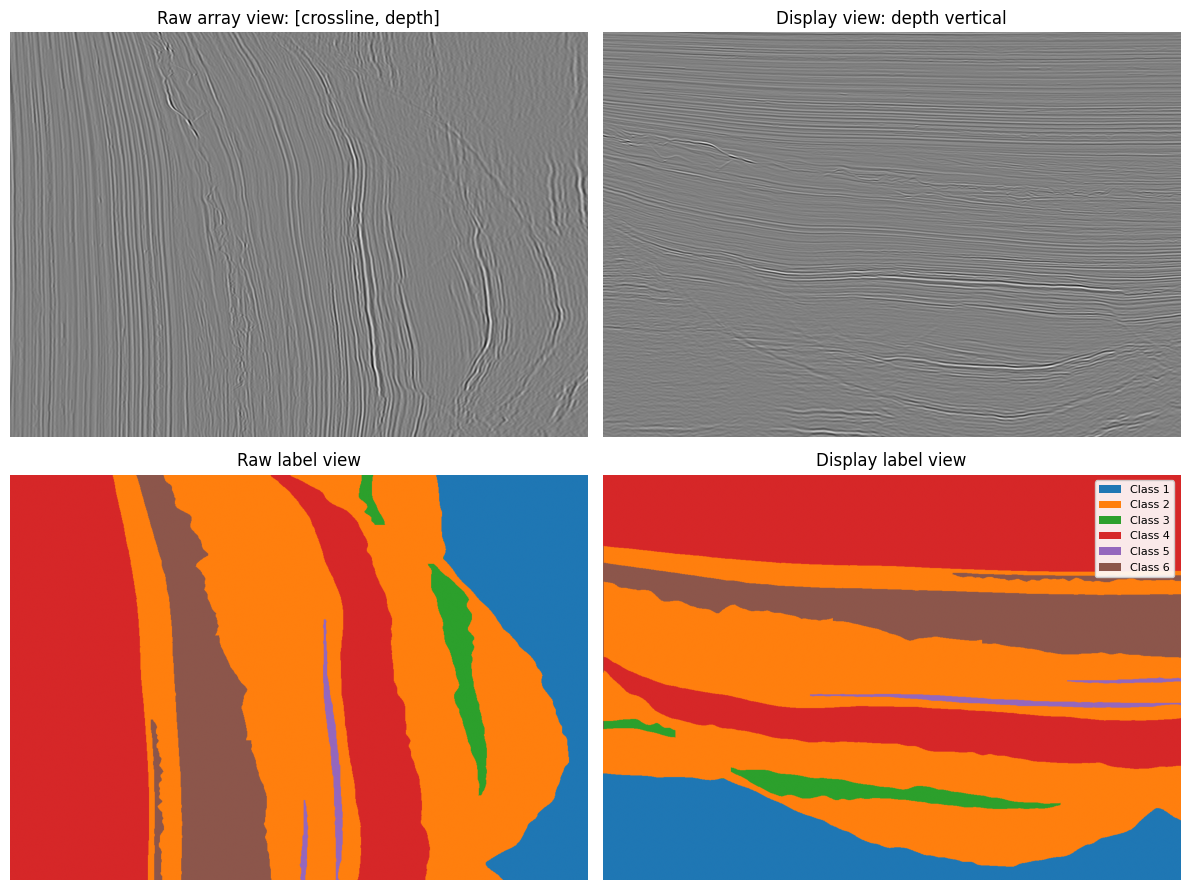

In [7]:
# Axis QC: the canonical volume order is [inline, crossline, depth].
# Raw inline sections are [crossline, depth]; transpose them to display depth vertically.
from src.visualization import FACIES_CMAP, FACIES_NORM, add_facies_legend, display_section
import matplotlib.pyplot as plt

qc_idx = train_seismic.shape[0] // 2
raw_seis = train_seismic[qc_idx]
raw_lab = train_labels[qc_idx]
print('volume shape [inline, crossline, depth]:', train_seismic.shape)
print('raw inline section shape [crossline, depth]:', raw_seis.shape)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].imshow(raw_seis, cmap='gray', aspect='auto')
axes[0, 0].set_title('Raw array view: [crossline, depth]')
axes[0, 1].imshow(display_section(raw_seis), cmap='gray', aspect='auto')
axes[0, 1].set_title('Display view: depth vertical')
axes[1, 0].imshow(raw_lab, cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
axes[1, 0].set_title('Raw label view')
axes[1, 1].imshow(display_section(raw_lab), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
axes[1, 1].set_title('Display label view')
add_facies_legend(axes[1, 1])
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

In [8]:
from src.dataset import SeismicSliceDataset, FullInlineValidationDataset
from src.comparison_protocol import verify_evaluation_indices

train_ds = SeismicSliceDataset(
    train_seismic, train_labels, split, normalization,
    mode='train', orientations=cfg['dataset']['orientations'],
    patch_size=cfg['dataset']['patch_size'], random_crop=cfg['dataset']['random_crop'],
    feature_mode=cfg['feature_engineering']['mode'], crop_strategy=cfg['dataset'].get('crop_strategy'),
    augmentation=cfg['augmentation'], samples_per_epoch=cfg['dataset']['samples_per_epoch'],
    random_sample_when_limited=cfg['dataset'].get('random_sample_when_limited', True),
    require_all_orientations=cfg['dataset'].get('require_all_orientations', False),
    balance_orientations=cfg['dataset'].get('balance_orientations', False),
    class_aware_sampling=cfg['dataset'].get('class_aware_sampling', False),
    class_aware_fraction=cfg['dataset'].get('class_aware_fraction', 0.5),
    global_context_fraction=cfg['dataset'].get('global_context_fraction', 0.0), seed=cfg['seed'],
)
if cfg.get('validation', {}).get('mode') == 'full_inline':
    val_ds = FullInlineValidationDataset(
        train_seismic, train_labels, split, normalization,
        feature_mode=cfg['feature_engineering']['mode'],
        max_sections=cfg['validation'].get('max_sections', 8),
        diagnostic_patch_size=cfg['dataset']['patch_size'],
    )
    print('full validation inline indices:', [idx for _, idx in val_ds.indices])
    print('full validation class support:', val_ds.class_support)
else:
    val_ds = SeismicSliceDataset(
        train_seismic, train_labels, split, normalization,
        mode='val', orientations=cfg['dataset']['orientations'],
        patch_size=cfg['dataset']['patch_size'], random_crop=False,
        feature_mode=cfg['feature_engineering']['mode'], crop_strategy=cfg['dataset'].get('crop_strategy'),
        augmentation={}, samples_per_epoch=cfg['dataset'].get('val_samples_per_epoch'),
        random_sample_when_limited=cfg['dataset'].get('random_sample_when_limited', True),
        require_all_orientations=cfg['dataset'].get('require_all_orientations', False),
        balance_orientations=cfg['dataset'].get('balance_orientations', False), seed=cfg['seed'] + 1,
    )
if not getattr(val_ds, 'full_inline', False):
    raise ValueError('The comparison requires full-inline validation.')
validation_indices = [idx for _, idx in val_ds.indices]
verify_evaluation_indices(split, validation_indices, resolve_path(cfg, 'outputs/comparison_v2/evaluation_indices.json'))
print('Shared validation inlines:', validation_indices)
print('Shared labeled test ranges:', split['test_ranges'])
batch0 = train_ds[0]
import math
from collections import Counter
print('train samples', len(train_ds), 'val samples', len(val_ds))
print('train orientations', Counter([orientation for orientation, _ in train_ds.indices]))
print('val orientations', Counter([orientation for orientation, _ in val_ds.indices]))
print('train steps/epoch', math.ceil(len(train_ds) / cfg['training']['batch_size']))
print('train batch size', cfg['training']['batch_size'])
print('validation mode', cfg.get('validation', {}).get('mode', 'patch'))
print('epochs', cfg['training']['epochs'], 'num_workers', cfg['training']['num_workers'])
print(batch0['image'].shape, batch0['mask'].shape, batch0['orientation'], batch0['index'])

full validation inline indices: [386, 396, 407, 417, 428, 449, 460, 471]
full validation class support: [1214087, 2563232, 97367, 1835472, 2616, 580762]
Shared validation inlines: [386, 396, 407, 417, 428, 449, 460, 471]
Shared labeled test ranges: [[0, 31], [107, 138], [558, 590]]
train samples 4096 val samples 8
train orientations Counter({'crossline': 780, 'inline': 348})
val orientations Counter({'inline': 8})
train steps/epoch 16
train batch size 256
validation mode full_inline
epochs 15 num_workers 4
torch.Size([3, 224, 224]) torch.Size([224, 224]) crossline 68


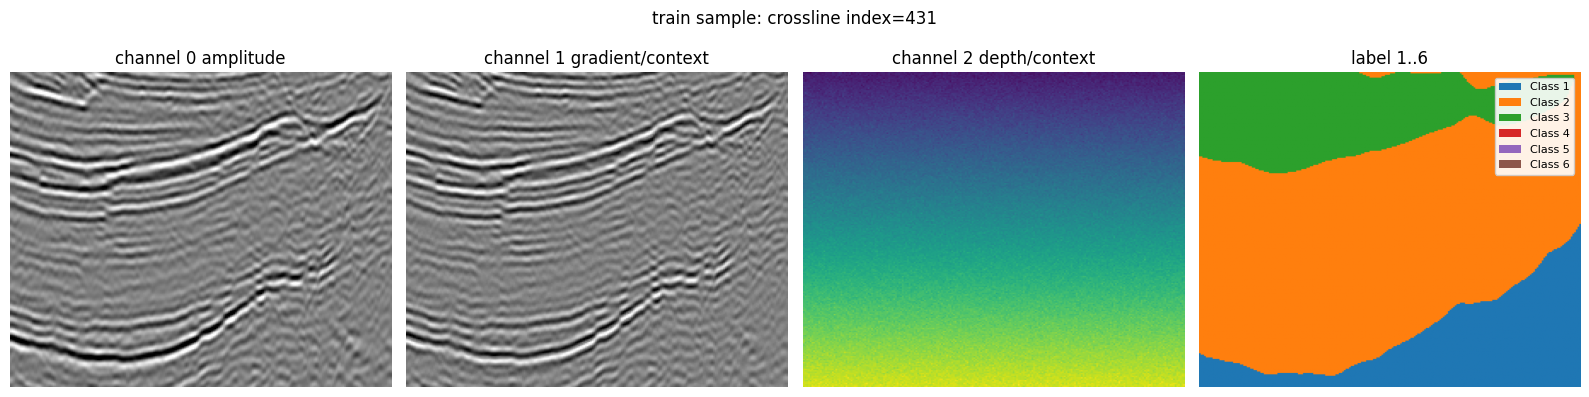

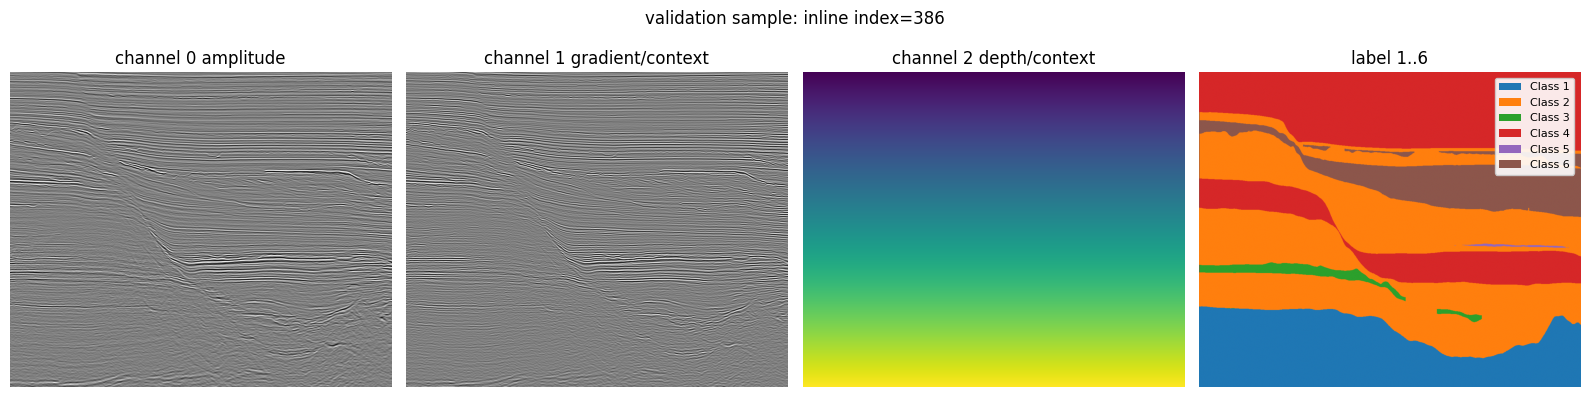

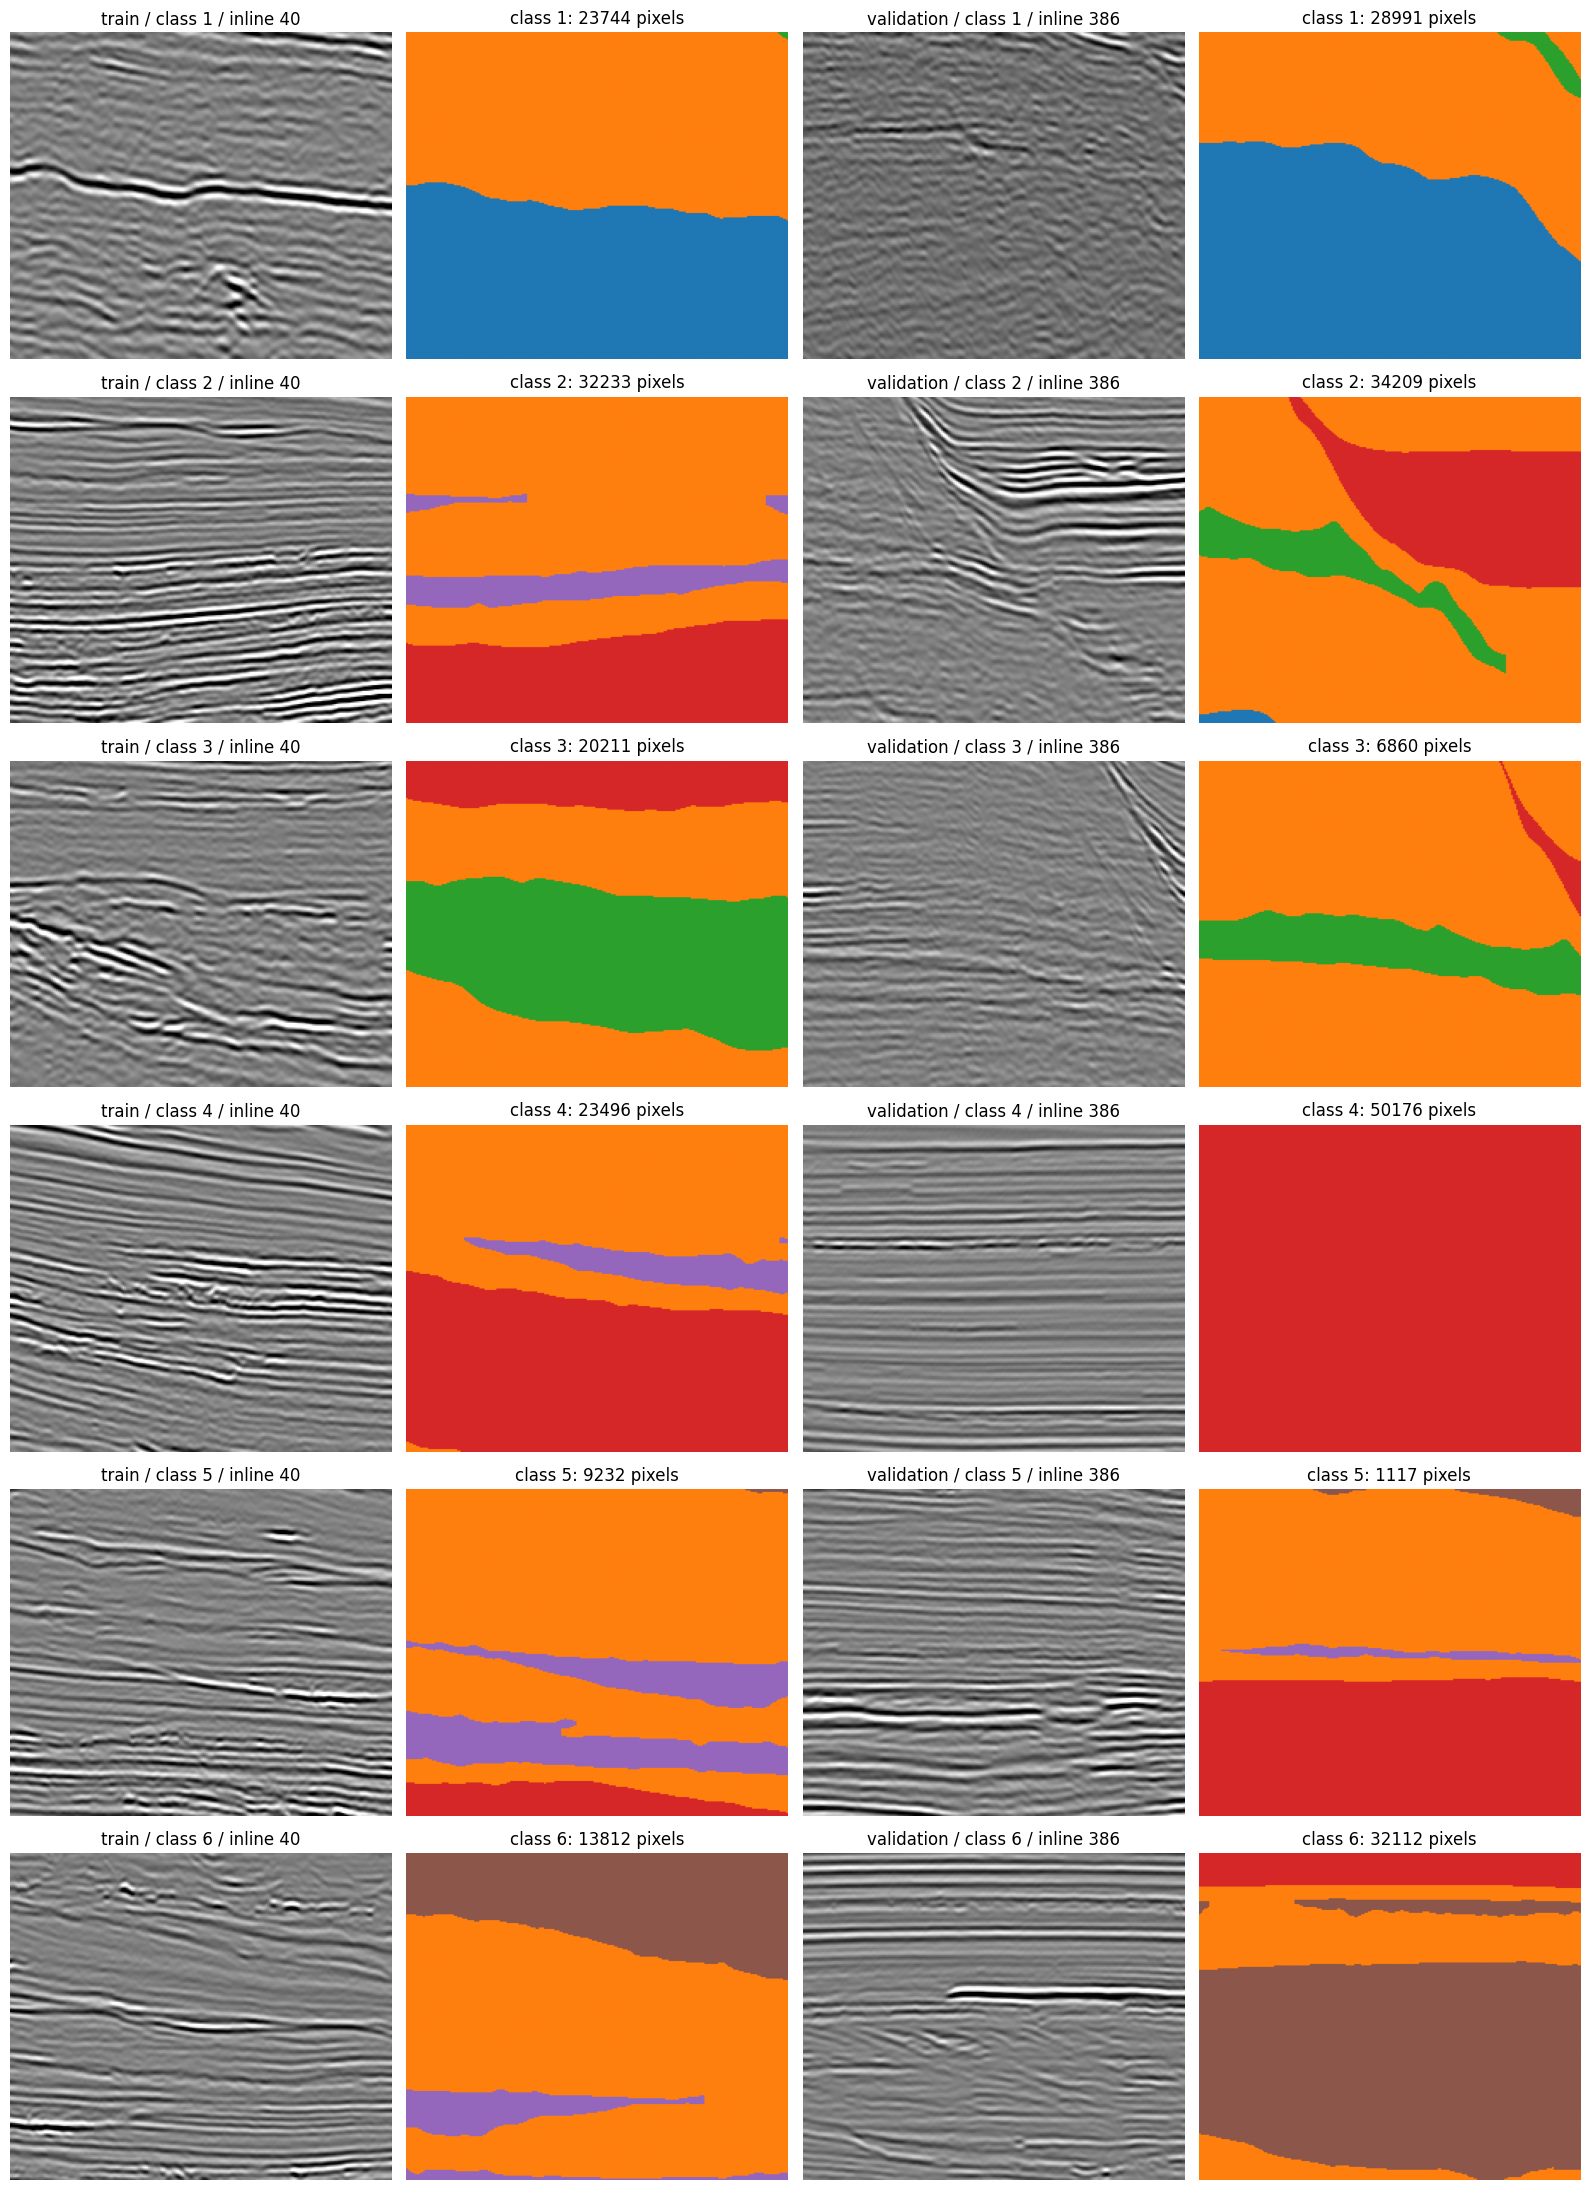

In [9]:
# Dataset QC: check that the model features and labels show the same section.
from src.visualization import FACIES_CMAP, FACIES_NORM, add_facies_legend, display_section
import matplotlib.pyplot as plt

def show_dataset_item(ds, idx, title):
    item = ds[idx]
    image = item['image'].numpy()
    mask = item['mask'].numpy() + 1
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(display_section(image[0]), cmap='gray', aspect='auto')
    axes[0].set_title('channel 0 amplitude')
    axes[1].imshow(display_section(image[1]), cmap='gray', aspect='auto')
    axes[1].set_title('channel 1 gradient/context')
    axes[2].imshow(display_section(image[2]), cmap='viridis', aspect='auto')
    axes[2].set_title('channel 2 depth/context')
    axes[3].imshow(display_section(mask), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
    axes[3].set_title('label 1..6')
    add_facies_legend(axes[3])
    fig.suptitle(f"{title}: {item['orientation']} index={item['index']}")
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_dataset_item(train_ds, 0, 'train sample')
show_dataset_item(val_ds, 0, 'validation sample')

# Show one real example from the training and validation regions for each class.
# These selected examples do not contribute to the validation score.
fig, axes = plt.subplots(6, 4, figsize=(16, 22))
for row, class_label in enumerate(range(1, 7)):
    for side, (name, ds) in enumerate((('train', train_ds), ('validation', val_ds))):
        item = ds.example_for_class(class_label)
        ax_image, ax_mask = axes[row, side * 2:side * 2 + 2]
        if item is None:
            ax_image.text(0.5, 0.5, f'No suitable {name} patch for class {class_label}', ha='center', va='center')
            ax_image.set_title(f'{name} / class {class_label}')
            ax_mask.axis('off')
            continue
        image = item['image'][0].numpy()
        mask = item['mask'].numpy() + 1
        count = int((mask == class_label).sum())
        ax_image.imshow(display_section(image), cmap='gray', aspect='auto')
        ax_image.set_title(f'{name} / class {class_label} / {item["orientation"]} {item["index"]}')
        ax_mask.imshow(display_section(mask), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
        ax_mask.set_title(f'class {class_label}: {count} pixels')
        for ax in (ax_image, ax_mask):
            ax.axis('off')
plt.tight_layout()
plt.show()


In [10]:
from src.models import build_model

model = build_model(cfg)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
with torch.no_grad():
    smoke = batch0['image'].unsqueeze(0).to(device)
    logits = model(smoke)
print('logits', logits.shape)
assert logits.shape[1] == 6

logits torch.Size([1, 6, 224, 224])


In [11]:
# Optional sanity test: can the model overfit a single example?
# Set RUN_TINY_OVERFIT_TEST=True to train a separate debug model on one sample for 30 steps.
# If loss does not clearly decrease, check feature-label alignment and the model or loss.
RUN_TINY_OVERFIT_TEST = False
if RUN_TINY_OVERFIT_TEST:
    from src.losses import build_loss
    debug_model = build_model(cfg).to(device)
    debug_model.train()
    debug_opt = torch.optim.AdamW(debug_model.parameters(), lr=cfg['training']['decoder_lr'])
    debug_loss_fn = build_loss('ce_dice', None, cfg['model']['num_classes'])
    x = batch0['image'].unsqueeze(0).to(device)
    y = batch0['mask'].unsqueeze(0).to(device)
    losses = []
    for step in range(30):
        debug_opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16, enabled=torch.cuda.is_available() and torch.cuda.is_bf16_supported()):
            loss = debug_loss_fn(debug_model(x), y)
        loss.backward()
        debug_opt.step()
        losses.append(float(loss.detach().cpu()))
    print('tiny overfit first/last loss:', losses[0], losses[-1])
    plt.plot(losses)
    plt.title('Tiny overfit loss')
    plt.xlabel('step')
    plt.ylabel('loss')
    plt.show()
    del debug_model
    torch.cuda.empty_cache()

Output directory: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet


2026/10/26 12:02:40 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


train 0:   0%|          | 0/16 [00:00<?, ?it/s]

validate full inline:   0%|          | 0/8 [00:00<?, ?it/s]

train 1:   0%|          | 0/16 [00:00<?, ?it/s]

...

train 14:   0%|          | 0/16 [00:00<?, ?it/s]

validate full inline:   0%|          | 0/8 [00:00<?, ?it/s]

🏃 View run seismic_unet-comparison-v2 at: https://dagshub.com/dragnellstr/sismoML.mlflow/#/experiments/2/runs/50b1fa5e612e49d0b67a33d0516bbbfa
🧪 View experiment at: https://dagshub.com/dragnellstr/sismoML.mlflow/#/experiments/2


2026/10/26 12:13:54 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/26 12:13:54 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


Saved training files:
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/split_inline.json 1392 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/normalization_train_only.json 746 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/logs/run_status.json 80 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/logs/experiment_results.csv 8377 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/logs/batch_losses.csv 15771 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/logs/last_validation_metrics.json 4522 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/logs/best_validation_metrics.json 4522 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/checkpoints/best_model.pth 99535793 bytes
  /content/drive/MyDrive/parihaka_dino_une

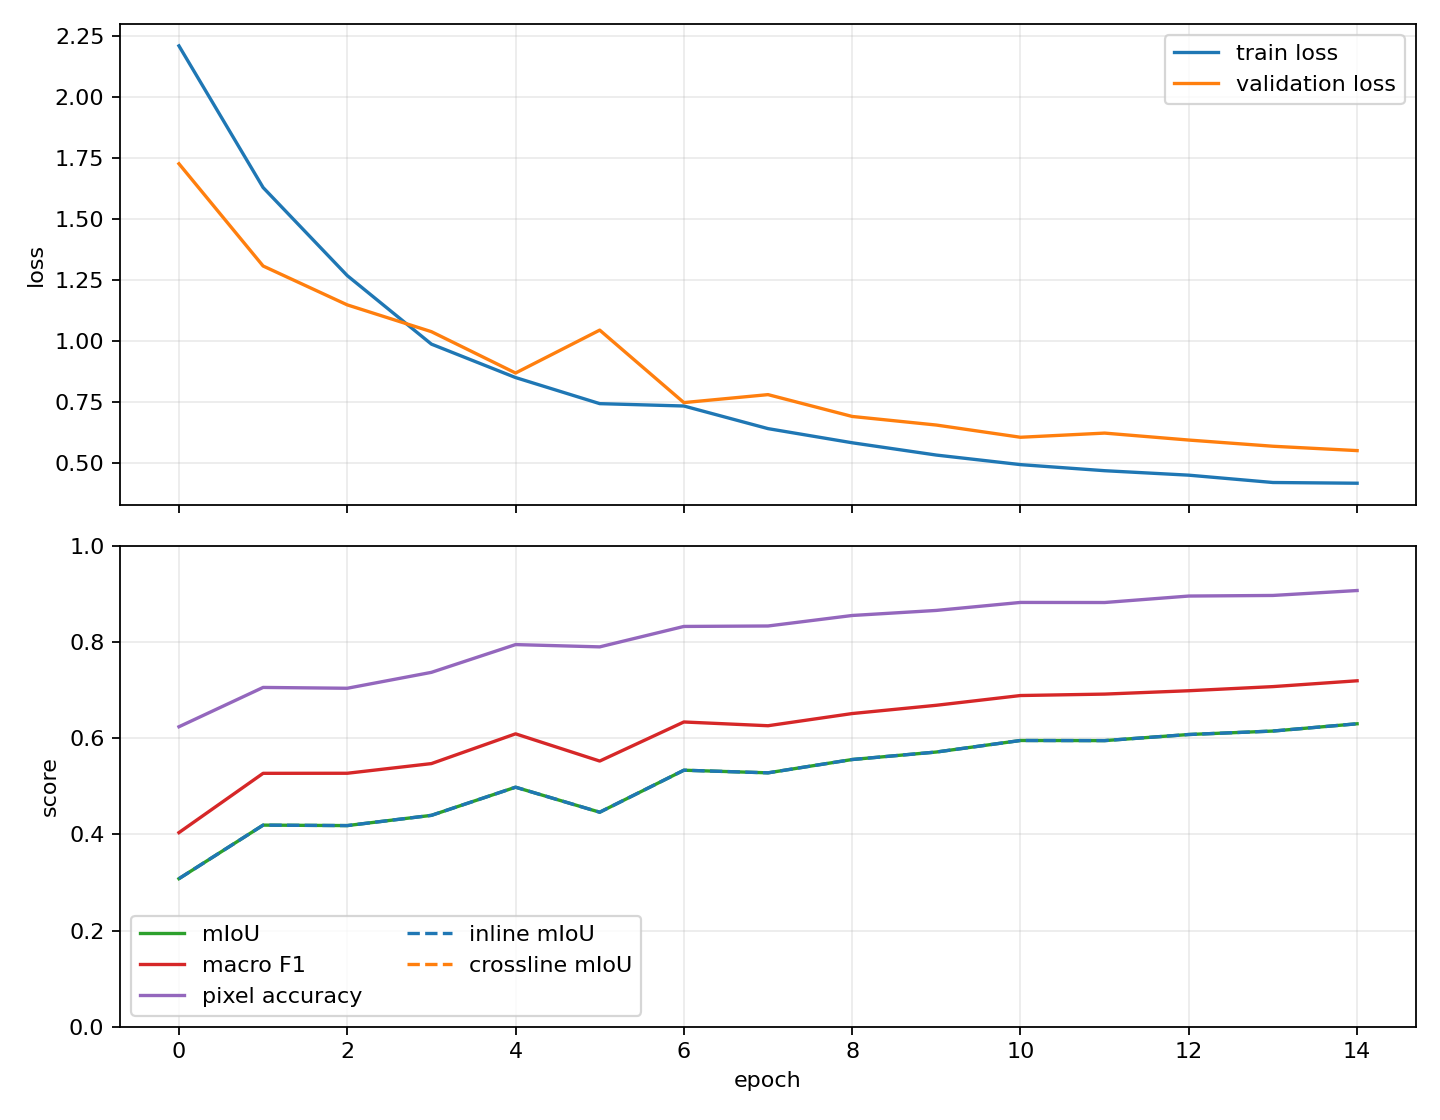

,epoch,train_loss,val_loss,val_nll,miou,class_iou,class_f1,macro_f1,weighted_f1,pixel_accuracy,mean_class_accuracy,frequency_weighted_iou,inline_miou,crossline_miou,inline_macro_f1,crossline_macro_f1,lr,lr_groups,epoch_time_sec,peak_gpu_gb
5,5,0.743950,1.045125,0.560453,0.445965,"[0.8019557866397754, 0.5995549005925979, 0.226...","[0.8900948542530388, 0.7496521693259505, 0.369...",0.552285,0.775500,0.789637,0.611575,0.655468,0.445965,NaN,0.552285,NaN,0.000219,[0.000219328432824252],39.536578,50.512152
6,6,0.734276,0.748193,0.386401,0.533254,"[0.9091457479754554, 0.6461043010511975, 0.278...","[0.9524110445098859, 0.7850101608246781, 0.435...",0.633506,0.837589,0.832098,0.743872,0.732681,0.533254,NaN,0.633506,NaN,0.000189,[0.00018920923308877476],42.030664,50.512152
7,7,0.641598,0.780875,0.397785,0.527804,"[0.9116125323368784, 0.6541734059215216, 0.223...","[0.9537628749718067, 0.7909369157788979, 0.365...",0.625708,0.839299,0.833029,0.764159,0.735306,0.527804,NaN,0.625708,NaN,0.000157,[0.00015749999999999998],40.460025,50.512152
8,8,0.583649,0.691458,0.333719,0.555474,"[0.9129903880712554, 0.6992326186407827, 0.284...","[0.9545164406097876, 0.8229981121714804, 0.443...",0.651036,0.859991,0.854872,0.746175,0.763729,0.555474,NaN,0.651036,NaN,0.000126,[0.00012579076691122517],44.639166,50.512152
9,9,0.533294,0.656263,0.314884,0.571061,"[0.9131882606609804, 0.7126404066037395, 0.298...","[0.9546245703446731, 0.832212534348579, 0.4594...",0.668219,0.868343,0.865390,0.754784,0.775907,0.571061,NaN,0.668219,NaN,0.000096,[9.567156717574795e-05],33.380541,50.512152
10,10,0.494150,0.606208,0.283819,0.595045,"[0.9194975123688196, 0.7423111934395211, 0.325...","[0.9580606449800324, 0.8520994369256323, 0.491...",0.688489,0.884786,0.882009,0.803034,0.800677,0.595045,NaN,0.688489,NaN,0.000069,[6.865270323513047e-05],36.440848,50.512152
11,11,0.469234,0.623271,0.290938,0.594784,"[0.9159640980575237, 0.7444400130833667, 0.326...","[0.9561391040533196, 0.8535002722937312, 0.492...",0.691467,0.883170,0.881832,0.774705,0.797961,0.594784,NaN,0.691467,NaN,0.000046,[4.6089013748305756e-05],37.362817,50.512152
12,12,0.450933,0.594799,0.263137,0.607469,"[0.9182061894387796, 0.771606786802065, 0.3223...","[0.9573592187265587, 0.8710813173107059, 0.487...",0.698450,0.896618,0.895281,0.759876,0.819380,0.607469,NaN,0.698450,NaN,0.000029,[2.9111936323905284e-05],46.126818,50.512152
13,13,0.420890,0.569424,0.252847,0.614659,"[0.9200406772704265, 0.771330855307633, 0.3459...","[0.9583554016974029, 0.8709054584539186, 0.514...",0.707037,0.898147,0.896514,0.772439,0.821789,0.614659,NaN,0.707037,NaN,0.000019,[1.8572772514090133e-05],34.136196,50.512152
14,14,0.417957,0.551569,0.237913,0.629774,"[0.9219160785742226, 0.7947200117698475, 0.361...","[0.9593718361086275, 0.8856200483173321, 0.531...",0.719154,0.907793,0.906759,0.788832,0.836666,0.629774,NaN,0.719154,NaN,0.000015,[1.4999999999999999e-05],34.812953,50.512152


,epoch,step,batch_loss,running_loss,lr
220,13,12,0.406750,0.423545,0.000020
221,13,13,0.398639,0.421766,0.000020
222,13,14,0.422896,0.421841,0.000019
223,13,15,0.406621,0.420890,0.000019
224,14,0,0.435074,0.435074,0.000018
225,14,1,0.410234,0.422654,0.000018
226,14,2,0.417236,0.420848,0.000017
227,14,3,0.413011,0.418889,0.000017
228,14,4,0.414031,0.417917,0.000017
229,14,5,0.401814,0.415233,0.000016


2026/10/26 12:13:58 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


🏃 View run seismic_unet-comparison-v2 at: https://dagshub.com/dragnellstr/sismoML.mlflow/#/experiments/2/runs/50b1fa5e612e49d0b67a33d0516bbbfa
🧪 View experiment at: https://dagshub.com/dragnellstr/sismoML.mlflow/#/experiments/2


2026/10/26 12:14:38 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/10/26 12:14:42 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


MLflow run logged to: https://dagshub.com/dragnellstr/sismoML.mlflow run_id= 50b1fa5e612e49d0b67a33d0516bbbfa


{'epoch': 14,
 'train_loss': 0.4179573692381382,
 'val_loss': 0.5515686646103859,
 'val_nll': 0.23791265007858858,
 'miou': 0.6297744612319603,
 'class_iou': '[0.9219160785742226, 0.7947200117698475, 0.36154031453250285, 0.9057305627448013, 0.08639231431029538, 0.7083474854600925]',
 'class_f1': '[0.9593718361086275, 0.8856200483173321, 0.5310754454694806, 0.9505337013017078, 0.15904441364746255, 0.8292779911451331]',
 'macro_f1': 0.7191539059982907,
 'weighted_f1': 0.9077928439033881,
 'pixel_accuracy': 0.9067594115613226,
 'mean_class_accuracy': 0.7888324735377003,
 'frequency_weighted_iou': 0.8366664748099025,
 'inline_miou': 0.6297744612319603,
 'crossline_miou': None,
 'inline_macro_f1': 0.7191539059982907,
 'crossline_macro_f1': None,
 'lr': 1.4999999999999999e-05,
 'lr_groups': '[1.4999999999999999e-05]',
 'epoch_time_sec': 34.81295347213745,
 'peak_gpu_gb': 50.51215171813965}

In [12]:
from src.trainer import Trainer
from src.visualization import save_training_curves
from IPython.display import Image, display
import pandas as pd

trainer = Trainer(model, cfg, train_ds, val_ds, normalization, split, device=device)
print('Output directory:', resolve_path(cfg, cfg['outputs']['dir']).resolve())
history = trainer.fit()
required_after_training = [resolve_path(cfg, cfg['split']['path']),
                           resolve_path(cfg, cfg['normalization']['path']),
                           trainer.status_path, trainer.log_path, trainer.batch_log_path,
                           trainer.metrics_json, trainer.best_metrics_json, trainer.best_path, trainer.last_path]
missing_after_training = [str(path) for path in required_after_training if not path.exists()]
if missing_after_training:
    raise FileNotFoundError(f'Training finished but output files are missing: {missing_after_training}')
print('Saved training files:')
for path in required_after_training:
    print(' ', path.resolve(), path.stat().st_size, 'bytes')
curve_path = resolve_path(cfg, cfg['outputs']['figures']) / 'training_curves.png'
save_training_curves(history, curve_path)
display(Image(filename=str(curve_path)))
epoch_log = pd.read_csv(resolve_path(cfg, cfg['outputs']['logs']) / 'experiment_results.csv')
batch_log = pd.read_csv(resolve_path(cfg, cfg['outputs']['logs']) / 'batch_losses.csv')
display(epoch_log.tail(10))
display(batch_log.tail(20))
if trainer.tracker.enabled and getattr(trainer.tracker, 'run_id', None):
    import mlflow
    with mlflow.start_run(run_id=trainer.tracker.run_id):
        mlflow.log_artifacts(str(resolve_path(cfg, cfg['outputs']['logs'])), artifact_path='logs')
        mlflow.log_artifacts(str(resolve_path(cfg, cfg['outputs']['figures'])), artifact_path='figures')
    print('MLflow run logged to:', cfg['tracking']['mlflow']['tracking_uri'], 'run_id=', trainer.tracker.run_id)
history[-1] if history else None

In [13]:
from src.checkpoint import load_checkpoint

best_path = resolve_path(cfg, cfg['outputs']['checkpoints']) / 'best_model.pth'
ckpt = load_checkpoint(best_path, model, map_location=device)
normalization = ckpt['normalization']
split = ckpt['split']
verify_comparison_split(split)
if [idx for _, idx in val_ds.indices] != validation_indices:
    raise ValueError('Validation indices changed after loading the checkpoint.')
print('loaded best mIoU', ckpt['best_miou'])

loaded best mIoU 0.6297744612319603


validation mIoU: 0.6297744612319603
validation pixel NLL: 0.23791265007858858
validation macro/weighted F1: 0.7191539059982907 0.9077928439033881
validation pixel accuracy: 0.9067594115613226
orientation mIoU: {'inline': 0.6297744612319603}
full validation inline indices: [386, 396, 407, 417, 428, 449, 460, 471]
class IoU: [0.9219160785742226, 0.7947200117698475, 0.36154031453250285, 0.9057305627448013, 0.08639231431029538, 0.7083474854600925]
actual validation pixels / classes 1..6: [1214087, 2563232, 97367, 1835472, 2616, 580762]
predicted pixels / classes 1..6: [1286789, 2413864, 140023, 1879340, 12537, 560983]
class F1: [0.9593718361086275, 0.8856200483173321, 0.5310754454694806, 0.9505337013017078, 0.15904441364746255, 0.8292779911451331]
class NLL: [0.03078541288242284, 0.35971096368286315, 0.9243651084366368, 0.1019676241370868, 1.1842545225293537, 0.44364756075556916]


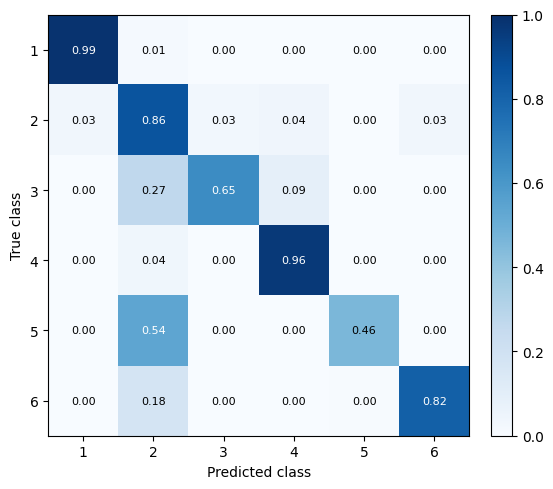

saved confusion matrix: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/figures/validation_confusion_matrix.png


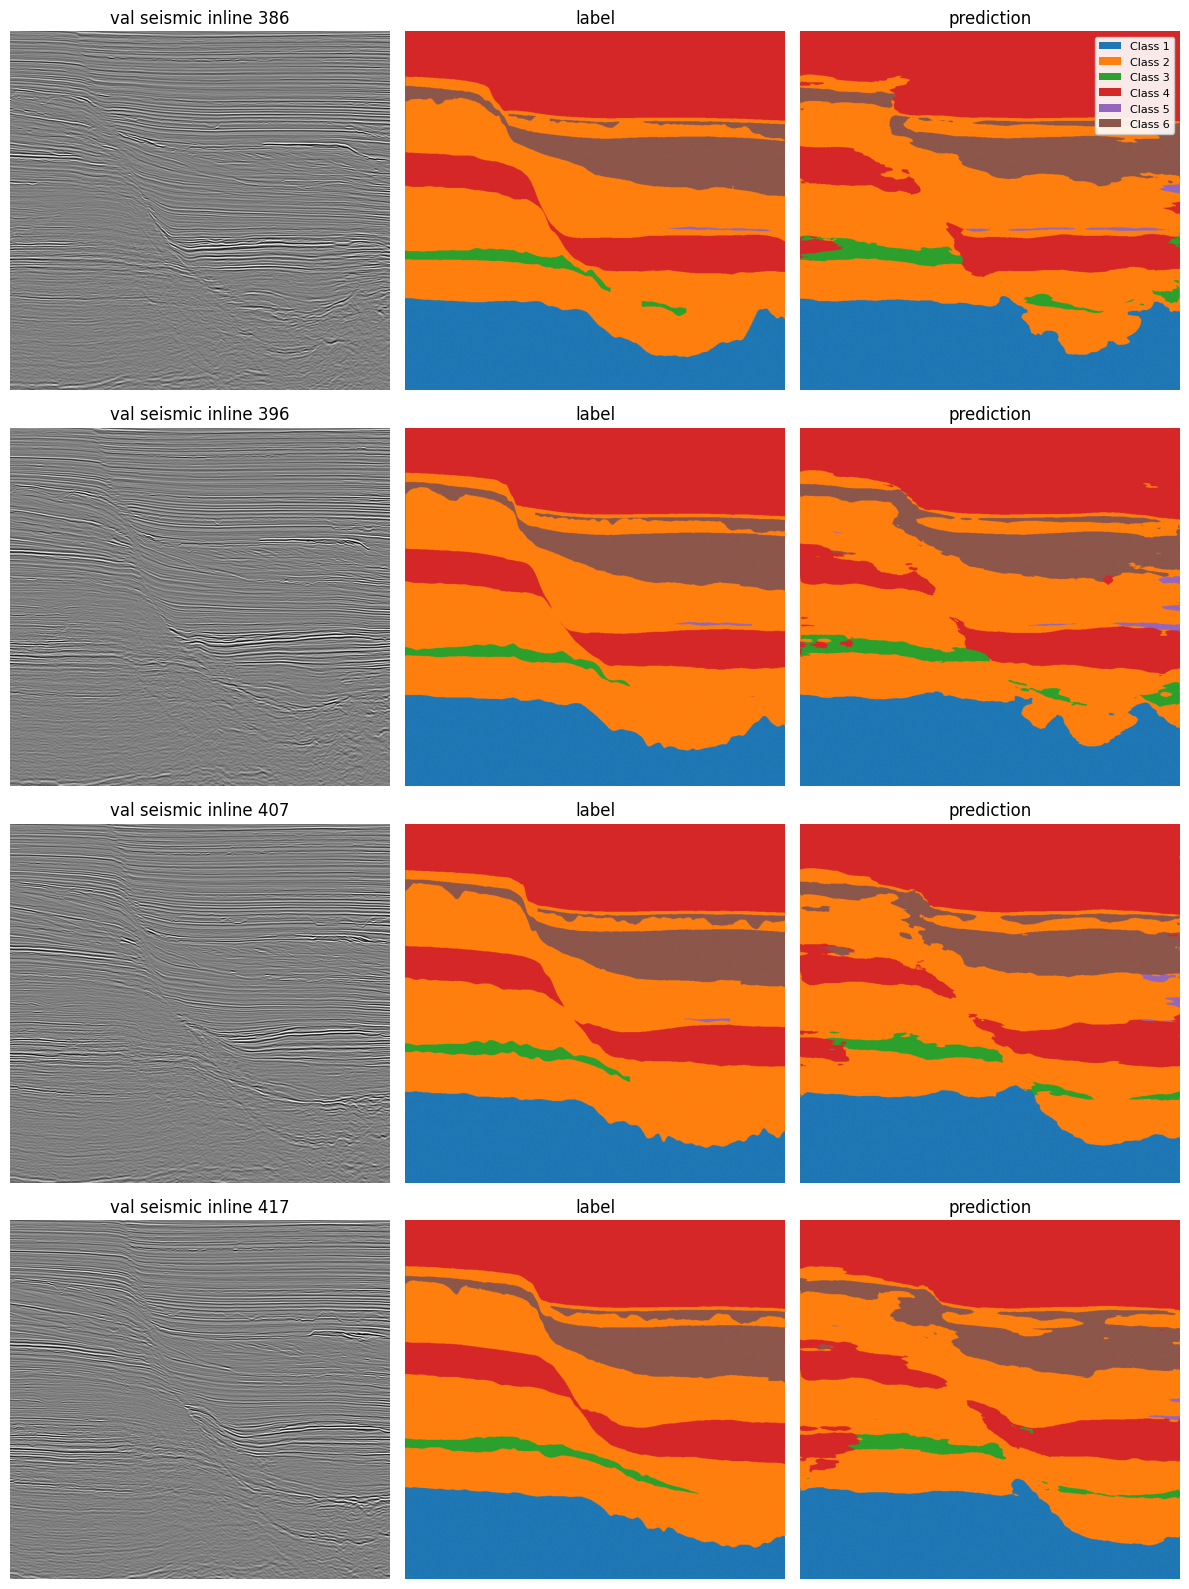

saved validation QC: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/figures/validation_prediction_qc.png


In [14]:
# Validation QC: confusion matrix and predictions on several real validation sections.
import json
import matplotlib.pyplot as plt
from src.visualization import FACIES_CMAP, FACIES_NORM, add_facies_legend, display_section, plot_confusion_matrix
from src.inference import predict_section
from src.features import make_triplet
from IPython.display import Image, display

metrics_path = resolve_path(cfg, cfg['outputs']['logs']) / 'best_validation_metrics.json'
metrics = json.load(open(metrics_path, 'r'))
print('validation mIoU:', metrics['miou'])
print('validation pixel NLL:', metrics.get('val_nll'))
print('validation macro/weighted F1:', metrics['macro_f1'], metrics['weighted_f1'])
print('validation pixel accuracy:', metrics['pixel_accuracy'])
print('orientation mIoU:', {k: v['miou'] for k, v in metrics.get('orientation_metrics', {}).items()})
print('full validation inline indices:', metrics.get('validation_inlines'))
print('class IoU:', metrics['class_iou'])
print('actual validation pixels / classes 1..6:', metrics.get('class_support'))
print('predicted pixels / classes 1..6:', metrics.get('class_predicted'))
print('class F1:', metrics['class_f1'])
print('class NLL:', metrics.get('class_nll'))
cm_path = resolve_path(cfg, cfg['outputs']['figures']) / 'validation_confusion_matrix.png'
fig = plot_confusion_matrix(np.array(metrics['confusion_matrix']), cm_path)
plt.show()
print('saved confusion matrix:', cm_path)

model.eval()
n_show = min(4, len(val_ds))
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4 * n_show))
axes = np.atleast_2d(axes)
with torch.no_grad():
    for row in range(n_show):
        item = val_ds[row]
        if getattr(val_ds, 'full_inline', False):
            triplet = make_triplet(train_seismic, 'inline', int(item['index']), bounds=tuple(split['val']))
            probs = predict_section(model, triplet, normalization, device, cfg)
            pred = probs.argmax(axis=0) + 1
        else:
            image = item['image'].unsqueeze(0).to(device)
            logits = model(image)
            pred = logits.argmax(dim=1).squeeze(0).cpu().numpy() + 1
        label = item['mask'].numpy() + 1
        seismic = item['image'][0].numpy()
        axes[row, 0].imshow(display_section(seismic), cmap='gray', aspect='auto')
        axes[row, 0].set_title(f"val seismic {item['orientation']} {item['index']}")
        axes[row, 1].imshow(display_section(label), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
        axes[row, 1].set_title('label')
        axes[row, 2].imshow(display_section(pred), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
        axes[row, 2].set_title('prediction')
        if row == 0:
            add_facies_legend(axes[row, 2])
        for col in range(3):
            axes[row, col].axis('off')
plt.tight_layout()
val_preview_path = resolve_path(cfg, cfg['outputs']['figures']) / 'validation_prediction_qc.png'
fig.savefig(val_preview_path, dpi=160)
plt.show()
print('saved validation QC:', val_preview_path)


In [15]:
# Independent labeled test: run once after selecting the best validation checkpoint.
from src.dataset import FullInlineValidationDataset
from src.evaluation import evaluate_labeled_inlines
import json

if 'test' not in split:
    raise RuntimeError('Checkpoint has no labeled test split; train with the updated train/val/test config.')
if ckpt['config']['model']['backbone'] != cfg['model']['backbone']:
    raise RuntimeError('Best checkpoint backbone does not match the current config.')
test_ds = FullInlineValidationDataset(
    train_seismic, train_labels, split, normalization,
    feature_mode=cfg['feature_engineering']['mode'],
    subset='test', max_sections=None,
    diagnostic_patch_size=cfg['dataset']['patch_size'],
)
print('labeled test ranges:', split['test_ranges'], 'complete inlines:', len(test_ds))
test_metrics = evaluate_labeled_inlines(model, test_ds, normalization, device, cfg)
test_metrics['checkpoint_epoch'] = int(ckpt['epoch'])
test_metrics['best_validation_miou'] = float(ckpt['best_miou'])
test_metrics_path = resolve_path(cfg, cfg['outputs']['logs']) / 'labeled_test_metrics.json'
with open(test_metrics_path, 'w', encoding='utf-8') as f:
    json.dump(test_metrics, f, indent=2)
print('labeled test mIoU:', test_metrics['miou'])
print('labeled test class IoU:', test_metrics['class_iou'])
print('labeled test class support:', test_metrics['class_support'])
print('missing test classes:', test_metrics['missing_test_classes'])
print('labeled test pixel NLL:', test_metrics['test_nll'])
print('saved:', test_metrics_path.resolve())

# Fixed first test inline for a comparable visual across all three models.
import matplotlib.pyplot as plt
import numpy as np
from src.features import make_triplet
from src.inference import predict_section
from src.visualization import FACIES_CMAP, FACIES_NORM, add_facies_legend, display_section, plot_confusion_matrix

test_cm_path = resolve_path(cfg, cfg['outputs']['figures']) / 'labeled_test_confusion_matrix.png'
fig = plot_confusion_matrix(np.asarray(test_metrics['confusion_matrix']), test_cm_path)
plt.close(fig)
test_item = test_ds[0]
test_idx = int(test_item['index'])
test_triplet = make_triplet(train_seismic, 'inline', test_idx, bounds=range_for_index(split, 'test', test_idx))
test_pred = predict_section(model, test_triplet, normalization, device, cfg).argmax(axis=0) + 1
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(display_section(test_item['image'][0].numpy()), cmap='gray', aspect='auto')
axes[0].set_title(f'test seismic inline {test_idx}')
axes[1].imshow(display_section(test_item['mask'].numpy() + 1), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
axes[1].set_title('label')
axes[2].imshow(display_section(test_pred), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
axes[2].set_title('prediction')
add_facies_legend(axes[2])
for ax in axes:
    ax.axis('off')
fig.tight_layout()
test_preview_path = resolve_path(cfg, cfg['outputs']['figures']) / 'labeled_test_prediction_qc.png'
fig.savefig(test_preview_path, dpi=160)
plt.close(fig)
print('saved test figures:', test_cm_path.resolve(), test_preview_path.resolve())


labeled test ranges: [[0, 31], [107, 138], [558, 590]] complete inlines: 94


test labeled inlines:   0%|          | 0/94 [00:00<?, ?it/s]

labeled test mIoU: 0.7592280341161701
labeled test class IoU: [0.960387099996602, 0.8142158977577887, 0.7429017265370134, 0.8766191447335454, 0.457079076295462, 0.7041652593766093]
labeled test class support: [11834429, 31313072, 4527496, 19669382, 1281905, 5322764]
missing test classes: []
labeled test pixel NLL: 0.22110390976555536
saved: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/logs/labeled_test_metrics.json
saved test figures: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/figures/labeled_test_confusion_matrix.png /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/figures/labeled_test_prediction_qc.png


In [16]:
# Portable manifest for the downloaded experiment folder.
import json as _json
from pathlib import Path as _Path
output_root = resolve_path(cfg, cfg['outputs']['dir']).resolve()
run_config_path = resolve_path(cfg, cfg['outputs']['logs']) / 'run_config.json'
with open(run_config_path, 'w', encoding='utf-8') as f:
    _json.dump(cfg, f, indent=2)
artifact_paths = required_after_training + [curve_path, cm_path, val_preview_path,
                           test_metrics_path, test_cm_path, test_preview_path, run_config_path]
files, missing_artifacts = {}, []
for path in artifact_paths:
    resolved = _Path(path).resolve()
    relative = resolved.relative_to(output_root).as_posix()
    if not resolved.is_file() or resolved.stat().st_size == 0:
        missing_artifacts.append(relative)
    else:
        files[relative] = resolved.stat().st_size
manifest_path = resolve_path(cfg, cfg['outputs']['logs']) / 'artifact_manifest.json'
with open(manifest_path, 'w', encoding='utf-8') as f:
    _json.dump({'schema_version': 1, 'model': cfg['model']['name'],
                'backbone': cfg['model'].get('backbone'),
                'run_name': cfg['tracking']['mlflow']['run_name'],
                'parameters_total': sum(p.numel() for p in model.parameters()),
                'parameters_trainable_final': sum(p.numel() for p in model.parameters() if p.requires_grad),
                'split': split, 'files': files, 'missing': missing_artifacts}, f, indent=2)
print('Artifact manifest:', manifest_path.resolve())
if missing_artifacts:
    raise FileNotFoundError(f'Missing artifacts: {missing_artifacts}')


Artifact manifest: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/seismic_unet/logs/artifact_manifest.json


## Training and evaluation outputs

- `outputs/logs/experiment_results.csv`: loss and classification metrics by epoch.
- `outputs/logs/best_validation_metrics.json`: validation metrics for the selected checkpoint epoch.
- `outputs/checkpoints/best_model.pth`: model selected by validation mIoU.
- `outputs/logs/labeled_test_metrics.json`: one-time evaluation of the selected model on the labeled test region.
- `outputs/figures/`: training curves, confusion matrices, and validation examples.
